<a href="https://colab.research.google.com/github/gaelosvaldor-star/Simulaci-n-2-/blob/main/Modelo_SIR_Metropolis_Gael_Rosales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="border-left:6px solid #2563eb;padding:18px;background:#eff6ff;color:#172554">
<h1>Modelo SIR: ajuste de parámetros con Metropolis</h1>
<p><b>Simulación II · ESFM 2027-1</b><br>Gael Osvaldo Rosales De La Cruz</p>
<p>Influenza en un internado: de las ecuaciones diferenciales a la distribución posterior.</p>
</div>




## 1. Problema y datos del material
*The inverse problem of a dynamical system solved with genetic algorithms* (2021), contiene los datos de influenza de un internado con $N=763$ alumnos. Se reproduce su **tabla 1**, sección 2.2. Cada observación corresponde al número de infectados presentes ese día, **no a nuevos contagios diarios**.

Se conocen $I(0)=1$ y $N$. Se supone $R(0)=0$, por lo que $S(0)=762$. El problema inverso consiste en encontrar parámetros cuyas trayectorias $I(t;a,b)$ describan las observaciones.

El artículo SIR usa un algoritmo genético y una distancia $L_1$. Aquí se conserva el modelo y el conjunto de datos y se construye un ajuste bayesiano con Metropolis, siguiendo la sección 7 del tutorial *An introduction to Markov Chain Monte Carlo* del material. La distribución del error y sus priors son decisiones de este cuaderno.


Versiones: {'Python': '3.13.16', 'NumPy': '2.1.3', 'SciPy': '1.16.3', 'ArviZ': '0.22.0'}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Infectados observados,1,3,6,25,73,222,294,258,237,191,125,69,27,11,4


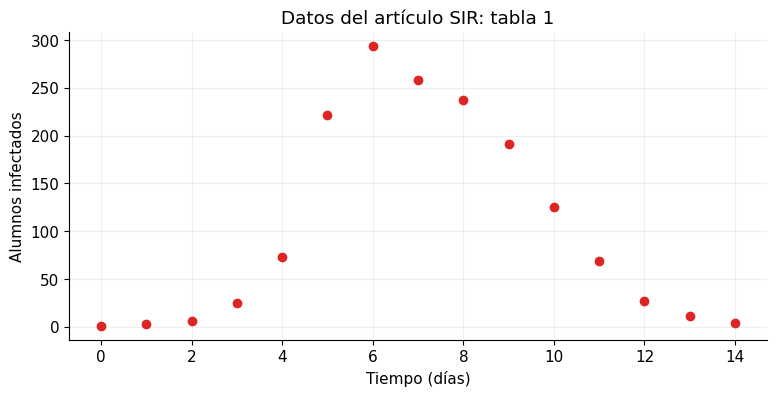

In [ ]:

import importlib.util
import subprocess
import sys
if importlib.util.find_spec("arviz") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "arviz"])

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import arviz as az
from scipy.integrate import odeint, solve_ivp, ODEintWarning
from scipy.optimize import least_squares
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
COLORES = ["#2563eb", "#dc2626", "#059669", "#9333ea"]
print("Versiones:", {"Python": sys.version.split()[0], "NumPy": np.__version__,
                     "SciPy": scipy.__version__, "ArviZ": az.__version__})

N = 763.0
Y0 = np.array([762.0, 1.0, 0.0])  # orden de los compartimentos: S, I, R
t_obs = np.arange(15, dtype=float)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4], dtype=float)
display(pd.DataFrame({"Día": t_obs.astype(int), "Infectados observados": i_obs.astype(int)}).T)
fig, ax = plt.subplots()
ax.scatter(t_obs, i_obs, color=COLORES[1], zorder=3)
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Datos del artículo SIR: tabla 1")
ax.grid(alpha=.2)
plt.show()


## 2. Modelo SIR y unidades

Se utiliza la convención del artículo, con **cantidades de alumnos**:

$$\frac{dS}{dt}=-aSI,\qquad
\frac{dI}{dt}=aSI-bI,\qquad
\frac{dR}{dt}=bI.$$

Aquí $a$ tiene unidades de alumno$^{-1}$ día$^{-1}$ y $b$ de día$^{-1}$. Se supone una población cerrada, mezcla homogénea, inmunidad después de recuperarse y tasas constantes. La suma de las ecuaciones es cero, por lo que $S+I+R=N$.

Si se escribe el contagio como $\beta SI/N$, la relación es $\beta=aN$. Por ello, el número reproductivo básico de esta convención es

$$\mathcal R_0=\frac{aN}{b},\qquad
\mathcal R_{\mathrm{ef}}(0)=\frac{aS(0)}{b}.$$

**Cuidado con la normalización:** el cociente $a/b$ que aparece en el PDF no es adimensional para las ecuaciones de conteos que implementamos. Se incluye $N$ al calcular $\mathcal R_0$. El crecimiento inicial requiere $aS(0)>b$.

### 2.1 Integración numérica

`odeint` llama al integrador LSODA. La función recibe el estado, el tiempo y los parámetros, y devuelve sus tres derivadas. Se revisan valores finitos, positividad y conservación de la población. No se recortan trayectorias inválidas para hacerlas parecer físicas.


In [ ]:
def sir_derivadas(y, t, a, b):
    S, I, R = y                       # desempaquetado de una secuencia
    contagios = a * S * I
    recuperaciones = b * I
    return [-contagios, contagios - recuperaciones, recuperaciones]

def resolver_sir(a, b, tiempos=t_obs, rtol=1e-7, atol=1e-7):
    """Integra desde t=0, aunque se pidan tiempos que comiencen después."""
    tiempos = np.asarray(tiempos, dtype=float)
    if (a <= 0 or b <= 0 or tiempos.ndim != 1 or len(tiempos) == 0
            or np.any(np.diff(tiempos) <= 0) or tiempos[0] < 0):
        raise ValueError("Parámetros positivos y tiempos crecientes requeridos.")
    agregar_cero = tiempos[0] > 0
    rejilla = np.r_[0.0, tiempos] if agregar_cero else tiempos
    with warnings.catch_warnings():
        warnings.simplefilter("error", ODEintWarning)
        sol = odeint(sir_derivadas, Y0, rejilla, args=(a, b),
                     rtol=rtol, atol=atol, mxstep=5000)
    if agregar_cero:
        sol = sol[1:]
    if (not np.isfinite(sol).all() or np.min(sol) < -1e-4
            or np.max(np.abs(sol.sum(axis=1) - N)) > 1e-3):
        raise ValueError("Solución numérica inválida.")
    return sol

ejemplo = resolver_sir(0.00205, 0.43552)
assert np.allclose(ejemplo[0], Y0)
assert np.max(np.abs(ejemplo.sum(axis=1) - N)) < 1e-3
print("Conservación de población comprobada; error máximo:",
      np.max(np.abs(ejemplo.sum(axis=1) - N)))


Conservación de población comprobada; error máximo: 7.958078640513122e-13


## 3. Modelo estadístico: qué estamos suponiendo

La tabla no proporciona errores de medición. Para hacer explícita la verosimilitud, se adopta la aproximación

$$I_j^{\mathrm{obs}}=I(t_j;a,b)+\epsilon_j,
\qquad \epsilon_j\overset{\mathrm{iid}}\sim\mathcal N(0,\sigma^2).$$

Además de $a$ y $b$, se estima una escala desconocida $\sigma$. Este ruido gaussiano independiente y de varianza constante es una **hipótesis de trabajo**, no una afirmación del artículo ni un modelo exacto de conteos. Permite discrepancias de medición y del modelo; sus limitaciones se discutirán con los residuos.

Como $I(0)=1$ se fija como condición inicial, ese mismo dato no vuelve a contarse como observación independiente. La verosimilitud usa los $n=14$ días de 1 a 14:

$$\log L(a,b,\sigma)=-n\log\sigma-\frac n2\log(2\pi)
-\frac{1}{2\sigma^2}\sum_{j=1}^{14}[I_j^{\mathrm{obs}}-I(t_j;a,b)]^2.$$

Se eligen priors independientes $a\sim U(0,1)$ y $b\sim U(0,1)$, con el mismo intervalo de búsqueda de los parámetros del artículo SIR. Para la escala se toma un prior propio, uniforme en su logaritmo: $p(\sigma)\propto1/\sigma$ para $0.1<\sigma<200$ alumnos. Los límites hacen que el prior sea normalizable. Los resultados son condicionales a estos priors, a las condiciones iniciales y al modelo del error.

Por Bayes, $p(a,b,\sigma\mid D)\propto L\,p(a)p(b)p(\sigma)$. La constante de normalización se cancela en la razón de aceptación.

### 3.1 Coordenadas para muestrear y Jacobiano

Para asegurar positividad y manejar escalas diferentes, se propone en

$$z=(\log(1000a),\log b,\log\sigma).$$

El factor 1000 sólo cambia la escala. La densidad en $z$ debe incluir el Jacobiano $a b\sigma$; el factor constante no afecta las razones. Como el prior de $\sigma$ es proporcional a $1/\sigma$, resulta

$$\log\pi_z(z)=\log L(a,b,\sigma)+\log a+\log b+C$$

dentro del soporte del prior; fuera del soporte vale $-\infty$. Omitir estos términos cambiaría los priors de $a$ y $b$.


In [ ]:
t_fit, i_fit = t_obs[1:], i_obs[1:]   # [1:] excluye la condición inicial
n_datos = len(i_fit)

def transformar(z):
    a = np.exp(z[0]) / 1000.0
    b = np.exp(z[1])
    sigma = np.exp(z[2])
    return a, b, sigma

def log_posterior_z(z):
    # Comprobar límites en logaritmos evita desbordar np.exp.
    if (not np.isfinite(z).all() or z[0] >= np.log(1000.0)
            or z[1] >= 0 or not np.log(.1) < z[2] < np.log(200.0)):
        return -np.inf
    a, b, sigma = transformar(z)
    if a == 0 or b == 0:
        return -np.inf
    try:
        pred = resolver_sir(a, b)[:, 1][1:]
    except (ValueError, RuntimeError, ODEintWarning, FloatingPointError):
        return -np.inf
    residuos = i_fit - pred
    logL = (-n_datos * np.log(sigma) - .5 * n_datos * np.log(2*np.pi)
            - .5 * np.dot(residuos, residuos) / sigma**2)
    return logL + np.log(a) + np.log(b)  # prior + Jacobiano, sin constantes

assert np.isfinite(log_posterior_z(np.log([2.05, .43552, 15.])))
assert log_posterior_z(np.log([2.05, 1.5, 15.])) == -np.inf


## 4. Metropolis: propuesta, aceptación y rechazos

Se propone un desplazamiento normal multivariado simétrico en $z$:

$$z'=z+sL\eta,\qquad \eta\sim\mathcal N(0,I_3),\qquad LL^T=C.$$

La probabilidad de aceptación es

$$\alpha=\min\left[1,\frac{\pi_z(z')}{\pi_z(z)}\right].$$

Se acepta cuando $\log u<\min[0,\log\pi_z(z')-\log\pi_z(z)]$, con $u\sim U(0,1)$. Trabajar con logaritmos evita subdesbordamientos.

**Un rechazo también es un paso de la cadena:** se guarda de nuevo el estado actual. Guardar sólo propuestas aceptadas produciría un muestreo incorrecto.

### 4.1 Una propuesta que respeta la correlación

Un ajuste preliminar por mínimos cuadrados sirve para localizar una región plausible y aproximar la covarianza de la propuesta. **Las estimaciones finales proceden de las cadenas**, no de este optimizador. Se generan cuatro estados iniciales distintos alrededor de esa región; el diagnóstico es local a la región explorada y no demuestra ausencia de otros modos.

Durante 3000 pasos de calentamiento se ajusta sólo la escala $s$ en bloques. Después se congela la propuesta, se descarta el calentamiento y se conservan 15000 pasos por cadena, incluidos los rechazos. No se aplica adelgazamiento.


In [ ]:
def residuos_para_iniciar(x):
    # x[0] representa 1000*a para mejorar la escala del optimizador.
    return resolver_sir(x[0]/1000.0, x[1])[:, 1][1:] - i_fit

inicio_ls = least_squares(residuos_para_iniciar, [2.0, .4],
                         bounds=([.01, .01], [20., .99]),
                         xtol=1e-10, ftol=1e-10, gtol=1e-10)
if not inicio_ls.success:
    raise RuntimeError(inicio_ls.message)
x_ls = inicio_ls.x
sigma_ls = np.sqrt(np.mean(inicio_ls.fun**2))
z_centro = np.log(np.r_[x_ls, sigma_ls])

# Aproximación local de covarianza: sigma^2 (J^T J)^(-1).
cov_x = sigma_ls**2 * np.linalg.inv(inicio_ls.jac.T @ inicio_ls.jac)
D = np.diag(1.0/x_ls)               # cambio de x a log(x)
cov_z = np.zeros((3, 3))
cov_z[:2, :2] = D @ cov_x @ D
cov_z[2, 2] = 1.0/(2*n_datos)       # escala aproximada de log(sigma)
L = np.linalg.cholesky(cov_z + np.eye(3)*1e-10)
print("Sólo inicialización LS:", {"a": x_ls[0]/1000, "b": x_ls[1], "sigma": sigma_ls})


Sólo inicialización LS: {'a': np.float64(0.0021806679412124915), 'b': np.float64(0.4452203579806166), 'sigma': np.float64(17.942518419194695)}


In [ ]:
def metropolis(z_inicial, semilla, n_warmup=3000, n_muestras=15000):
    """Caminata aleatoria simétrica; adaptación sólo en el calentamiento."""
    rng = np.random.default_rng(semilla)
    z = np.array(z_inicial, dtype=float).copy()
    logp = log_posterior_z(z)
    if not np.isfinite(logp):
        raise ValueError("El estado inicial debe tener posterior finita.")
    guardadas = np.empty((n_muestras, 3))
    calentamiento = np.empty((n_warmup, 3))
    escala = 2.38/np.sqrt(3)
    aceptadas = 0
    bloque = 0
    for paso in range(n_warmup + n_muestras):
        propuesta = z + escala * (L @ rng.normal(size=3))
        logp_nueva = log_posterior_z(propuesta)
        aceptar = np.log(rng.random()) < min(0.0, logp_nueva - logp)
        if aceptar:
            z, logp = propuesta, logp_nueva
        if paso < n_warmup:
            calentamiento[paso] = z
            bloque += int(aceptar)
            if (paso + 1) % 100 == 0:
                escala *= np.exp(bloque/100.0 - .30)
                escala = np.clip(escala, .1, 10.)
                bloque = 0
        else:
            guardadas[paso - n_warmup] = z  # también se escribe al rechazar
            aceptadas += int(aceptar)
    return guardadas, calentamiento, aceptadas/n_muestras, escala

SEED = 20261011
rng_inicios = np.random.default_rng(SEED)
inicios = []
while len(inicios) < 4:
    candidato = z_centro + 3.0 * (L @ rng_inicios.normal(size=3))
    if np.isfinite(log_posterior_z(candidato)):
        inicios.append(candidato)
display(pd.DataFrame([transformar(z) for z in inicios], columns=["a inicial", "b inicial", "sigma inicial"]))

tic = time.perf_counter()
resultados = []
for c, z0 in enumerate(inicios):
    resultado = metropolis(z0, SEED + c + 1)
    resultados.append(resultado)
    print(f"Cadena {c+1}: aceptación={resultado[2]:.3f}; escala final={resultado[3]:.3f}", flush=True)
cadenas_z = np.stack([r[0] for r in resultados])  # forma: (cadena, paso, parámetro)
warm_z = np.stack([r[1] for r in resultados])
cadenas = np.exp(cadenas_z)
cadenas[:, :, 0] /= 1000.0
print(f"Tiempo MCMC: {time.perf_counter()-tic:.1f} s; forma={cadenas.shape}")


,a inicial,b inicial,sigma inicial
0,0.002254,0.471971,10.736347
1,0.002081,0.453588,18.086550
2,0.002282,0.432356,15.174136
3,0.002207,0.469116,20.501216


Cadena 1: aceptación=0.372; escala final=1.320
Cadena 2: aceptación=0.329; escala final=1.459
Cadena 3: aceptación=0.302; escala final=1.565
Cadena 4: aceptación=0.261; escala final=1.678
Tiempo MCMC: 37.1 s; forma=(4, 15000, 3)


## 5. Diagnóstico antes de interpretar resultados

Una tasa de aceptación razonable no demuestra convergencia. Se revisan trazas, autocorrelación, $\widehat R$ normalizado por rangos y tamaños efectivos de muestra (ESS) para el centro y las colas. Se usan como criterios prácticos $\widehat R<1.01$ y ESS mayor que 400; son comprobaciones, no una prueba matemática de convergencia. El error Monte Carlo de la media (MCSE) mide precisión computacional, no incertidumbre del parámetro.

Las trazas deben explorar regiones compatibles sin tendencias persistentes; la autocorrelación debe decaer. Si fallan los criterios, se debe aumentar la longitud o revisar la propuesta y los inicios antes de interpretar el ajuste.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002183,0.000038,0.002106,0.002258,5.905308e-07,4.812938e-07,4309.009812,5614.313997,1.000868
b,0.446594,0.018125,0.410721,0.481626,2.716920e-04,3.161428e-04,4626.394383,5848.626425,1.000476
sigma,20.759676,4.672025,12.861454,29.868689,7.484515e-02,7.912473e-02,4461.594307,5362.722661,1.000861


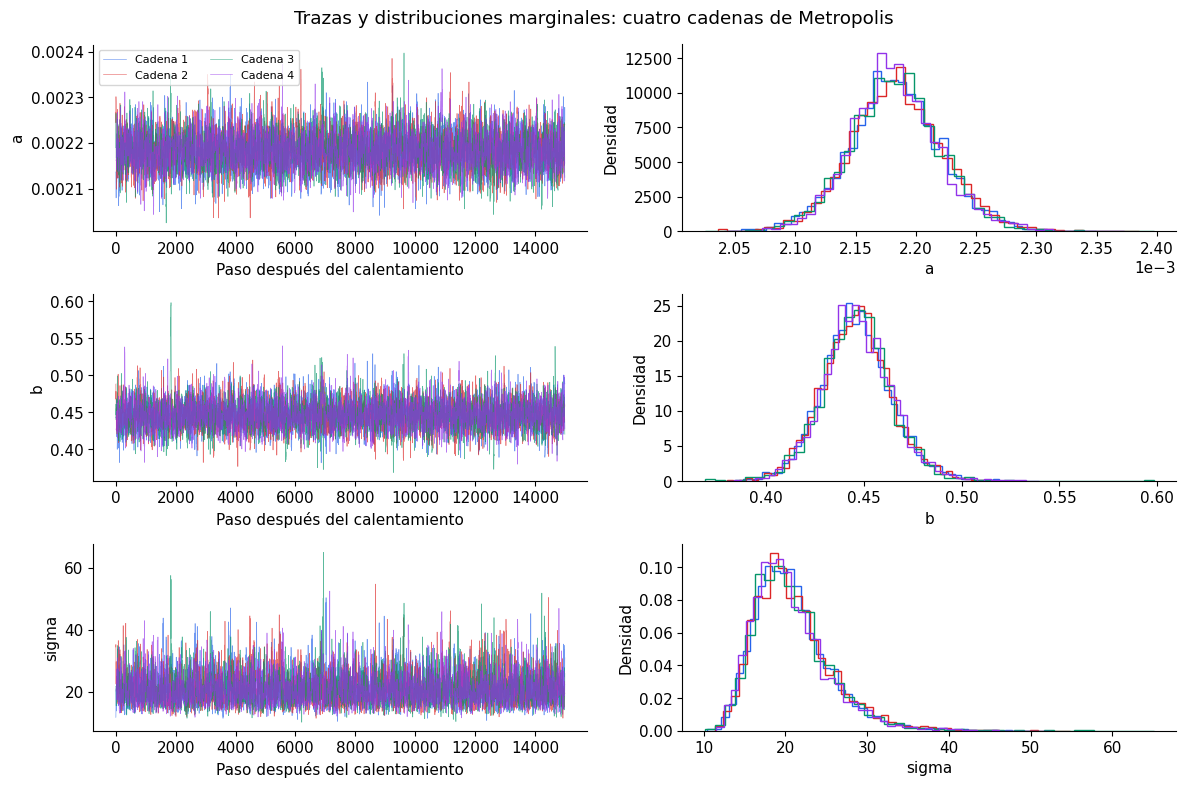

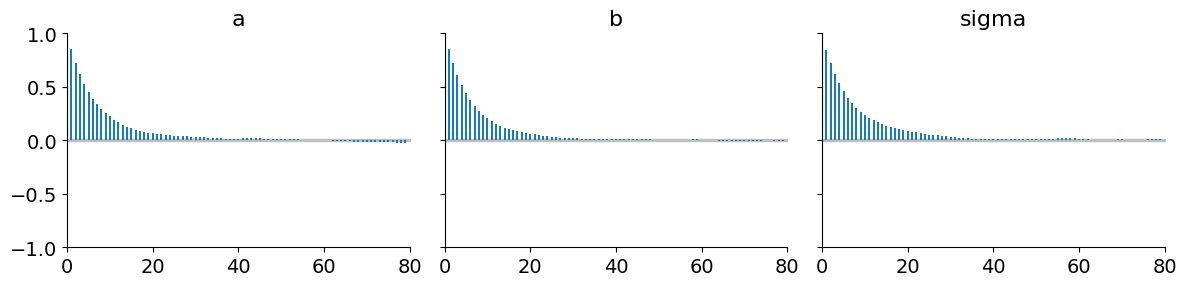

Criterios de diagnóstico satisfechos: True


In [ ]:
idata = az.from_dict(posterior={"a": cadenas[:, :, 0], "b": cadenas[:, :, 1],
                                "sigma": cadenas[:, :, 2]})
diagnostico = az.summary(idata, hdi_prob=.95, round_to="none")
display(diagnostico)

fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for k, nombre in enumerate(["a", "b", "sigma"]):
    for c in range(4):
        axes[k, 0].plot(cadenas[c, :, k], color=COLORES[c], lw=.45, alpha=.65, label=f"Cadena {c+1}")
        axes[k, 1].hist(cadenas[c, :, k], bins=45, density=True, histtype="step", color=COLORES[c])
    axes[k, 0].set(ylabel=nombre, xlabel="Paso después del calentamiento")
    axes[k, 1].set(xlabel=nombre, ylabel="Densidad")
axes[0, 1].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Trazas y distribuciones marginales: cuatro cadenas de Metropolis")
fig.tight_layout()
plt.show()
az.plot_autocorr(idata, var_names=["a", "b", "sigma"], combined=True, max_lag=80, figsize=(12, 3))
plt.tight_layout()
plt.show()

convergencia_ok = bool((diagnostico.r_hat < 1.01).all()
                      and (diagnostico.ess_bulk > 400).all()
                      and (diagnostico.ess_tail > 400).all())
print("Criterios de diagnóstico satisfechos:", convergencia_ok)
assert convergencia_ok, "Revisar mezcla o aumentar n_muestras antes de interpretar los resultados."


## 6. Estimaciones posteriores y solución final

Se reporta la **mediana posterior** y el intervalo creíble central del 95 %, calculado entre los percentiles 2.5 y 97.5. Este intervalo describe la incertidumbre bajo el modelo y los priors elegidos; no es un intervalo frecuentista. La tabla anterior de ArviZ usa intervalos HDI, que pueden diferir ligeramente de los centrales.

Se obtiene también $\mathcal R_0=aN/b$ y la duración media infecciosa $1/b$, transformando **cada muestra conjunta**, para conservar la correlación de los parámetros. Las medianas marginales no tienen por qué formar la muestra de mayor posterior.


,Límite 2.5%,Mediana,Límite 97.5%
a [alumno^-1 día^-1],0.002110,0.002182,0.002262
b [día^-1],0.412184,0.446161,0.483922
sigma [alumnos],13.894268,19.996300,31.929126
R0 = a*N/b,3.466991,3.731873,4.019178
R efectivo inicial = a*S0/b,3.462447,3.726982,4.013910
Duración infecciosa media [días],2.066447,2.241345,2.426102


### Solución final del ajuste
- **Transmisión a:** 0.0021825 (ICr 95 %: 0.0021097, 0.0022620) alumno⁻¹ día⁻¹.
- **Recuperación b:** 0.44616 (ICr 95 %: 0.41218, 0.48392) día⁻¹.
- **R₀:** 3.732 (ICr 95 %: 3.467, 4.019).
- **Duración media infecciosa:** 2.241 (ICr 95 %: 2.066, 2.426) días.

Los criterios numéricos de diagnóstico se satisficieron para las cadenas ejecutadas.

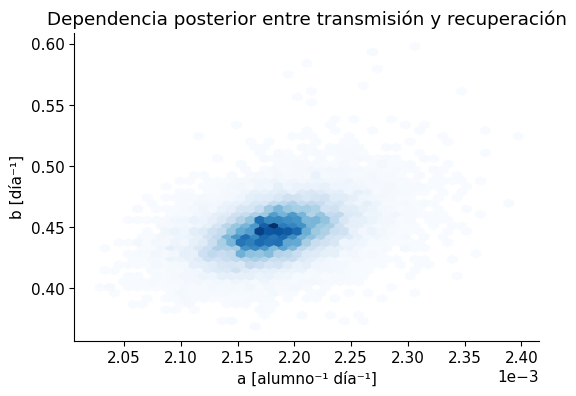

In [ ]:
muestras = cadenas.reshape(-1, 3)
valores = {
    "a [alumno^-1 día^-1]": muestras[:, 0],
    "b [día^-1]": muestras[:, 1],
    "sigma [alumnos]": muestras[:, 2],
    "R0 = a*N/b": muestras[:, 0]*N/muestras[:, 1],
    "R efectivo inicial = a*S0/b": muestras[:, 0]*Y0[0]/muestras[:, 1],
    "Duración infecciosa media [días]": 1.0/muestras[:, 1]
}
tabla_final = pd.DataFrame({nombre: np.quantile(v, [.025, .5, .975]) for nombre, v in valores.items()},
                           index=["Límite 2.5%", "Mediana", "Límite 97.5%"]).T
display(tabla_final.style.format("{:.6f}").set_caption("Solución posterior: intervalos centrales del 95 %"))
a_med, b_med, sigma_med = np.median(muestras, axis=0)

def formato_resultado(nombre, cifras=5):
    lo, med, hi = tabla_final.loc[nombre]
    return f"{med:.{cifras}f} (ICr 95 %: {lo:.{cifras}f}, {hi:.{cifras}f})"

display(Markdown(
    "### Solución final del ajuste\n"
    f"- **Transmisión a:** {formato_resultado('a [alumno^-1 día^-1]', 7)} alumno⁻¹ día⁻¹.\n"
    f"- **Recuperación b:** {formato_resultado('b [día^-1]')} día⁻¹.\n"
    f"- **R₀:** {formato_resultado('R0 = a*N/b', 3)}.\n"
    f"- **Duración media infecciosa:** {formato_resultado('Duración infecciosa media [días]', 3)} días.\n\n"
    "Los criterios numéricos de diagnóstico se satisficieron para las cadenas ejecutadas."
))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hexbin(muestras[:, 0], muestras[:, 1], gridsize=45, cmap="Blues", mincnt=1)
ax.set(xlabel="a [alumno⁻¹ día⁻¹]", ylabel="b [día⁻¹]", title="Dependencia posterior entre transmisión y recuperación")
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
plt.show()


## 7. Ajuste, incertidumbre y residuos

La banda azul muestra incertidumbre en la **trayectoria latente** $I(t)$, debida a los parámetros. La banda gris es una banda **predictiva de observaciones**: además agrega ruido gaussiano con la escala $\sigma$ de cada muestra. Ambas son intervalos puntuales del 95 %, no bandas simultáneas. La aproximación normal puede producir límites predictivos negativos; se muestran sin recortarlos para hacer visible esa limitación.

Las curvas $S$ y $R$ son predicciones del modelo porque sólo se observó $I$. Se contrastan los parámetros finales con los valores del ajuste genético del artículo: $a\approx0.00205$, $b\approx0.43552$. No se exige igualdad: cambian la función de ajuste y el tratamiento de la incertidumbre.


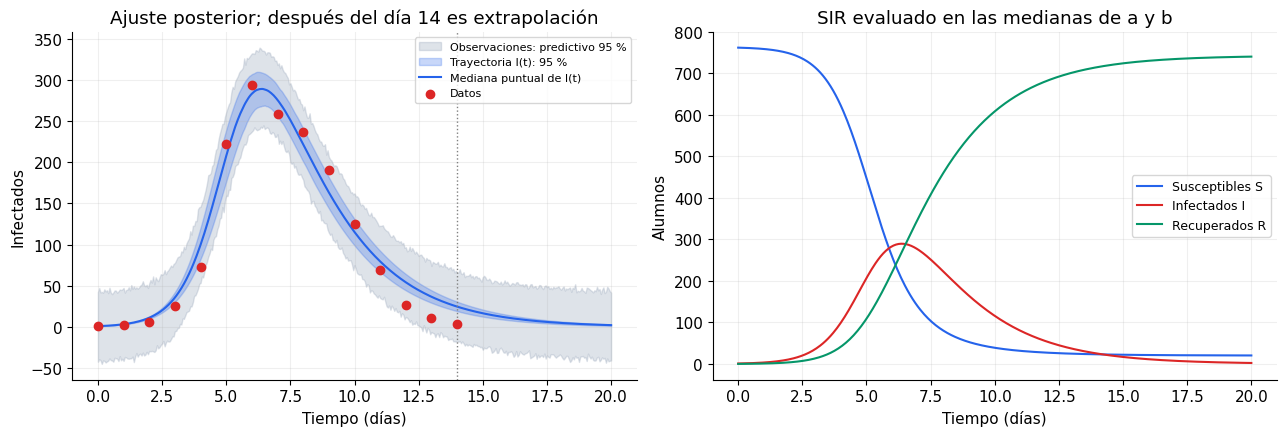

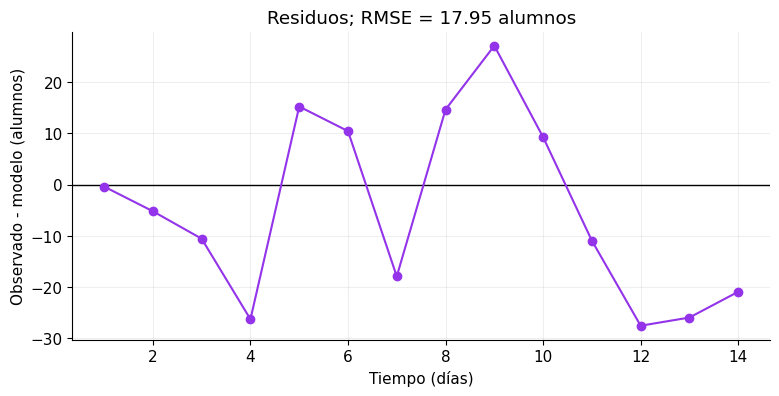

,a,b
Medianas Metropolis (este cuaderno),0.002182,0.446161
Algoritmo genético (artículo SIR),0.002050,0.435520


Correlación posterior a,b: 0.396
P(R efectivo inicial > 1 | datos): 1.0000


**Lectura del ajuste:** RMSE = 17.95 alumnos. Los residuos son negativos en los últimos cuatro días: el SIR ajustado sobreestima los infectados al final del intervalo. Esta estructura invita a revisar la hipótesis de error independiente y de escala constante, aunque la mezcla de las cadenas sea adecuada.

In [ ]:
t_fino = np.linspace(0, 20, 401)
sol_med = resolver_sir(a_med, b_med, t_fino)
rng_pred = np.random.default_rng(SEED + 100)
sub = muestras[rng_pred.choice(len(muestras), size=800, replace=False)]
curvas = np.stack([resolver_sir(a, b, t_fino)[:, 1] for a, b, sigma in sub])
bandas_modelo = np.quantile(curvas, [.025, .5, .975], axis=0)
replicas = curvas + rng_pred.normal(size=curvas.shape)*sub[:, 2, None]
bandas_pred = np.quantile(replicas, [.025, .975], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].fill_between(t_fino, *bandas_pred, color="#94a3b8", alpha=.3, label="Observaciones: predictivo 95 %")
axes[0].fill_between(t_fino, bandas_modelo[0], bandas_modelo[2], color=COLORES[0], alpha=.25, label="Trayectoria I(t): 95 %")
axes[0].plot(t_fino, bandas_modelo[1], color=COLORES[0], label="Mediana puntual de I(t)")
axes[0].scatter(t_obs, i_obs, color=COLORES[1], zorder=5, label="Datos")
axes[0].axvline(14, color="gray", ls=":", lw=1)
axes[0].set(xlabel="Tiempo (días)", ylabel="Infectados", title="Ajuste posterior; después del día 14 es extrapolación")
axes[0].legend(fontsize=8)
for k, etiqueta in enumerate(["Susceptibles S", "Infectados I", "Recuperados R"]):
    axes[1].plot(t_fino, sol_med[:, k], color=COLORES[k], label=etiqueta)
axes[1].set(xlabel="Tiempo (días)", ylabel="Alumnos", title="SIR evaluado en las medianas de a y b")
axes[1].legend(fontsize=9)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

pred_obs = resolver_sir(a_med, b_med)[:, 1]
residuos_finales = i_fit - pred_obs[1:]
rmse = np.sqrt(np.mean(residuos_finales**2))
fig, ax = plt.subplots()
ax.axhline(0, color="black", lw=1)
ax.plot(t_fit, residuos_finales, "o-", color=COLORES[3])
ax.set(xlabel="Tiempo (días)", ylabel="Observado - modelo (alumnos)", title=f"Residuos; RMSE = {rmse:.2f} alumnos")
ax.grid(alpha=.2)
plt.show()
comparacion = pd.DataFrame({"a": [a_med, .00205], "b": [b_med, .43552]},
                           index=["Medianas Metropolis (este cuaderno)", "Algoritmo genético (artículo SIR)"])
display(comparacion)
print(f"Correlación posterior a,b: {np.corrcoef(muestras[:, 0], muestras[:, 1])[0, 1]:.3f}")
print(f"P(R efectivo inicial > 1 | datos): {np.mean(valores['R efectivo inicial = a*S0/b'] > 1):.4f}")

display(Markdown(f"**Lectura del ajuste:** RMSE = {rmse:.2f} alumnos. Los residuos son negativos en los últimos cuatro días: el SIR ajustado sobreestima los infectados al final del intervalo. Esta estructura invita a revisar la hipótesis de error independiente y de escala constante, aunque la mezcla de las cadenas sea adecuada."))


## 8. Comprobación numérica independiente

Se compara la integración LSODA con `solve_ivp` y el método DOP853, usando tolerancias más estrictas, en las medianas posteriores. También se revisa la conservación de $N$ y la no negatividad. Esta prueba comprueba la integración en el ajuste obtenido; no valida por sí sola los supuestos epidemiológicos.


In [ ]:
ref = solve_ivp(lambda t, y: sir_derivadas(y, t, a_med, b_med),
                (0., float(t_obs[-1])), Y0, t_eval=t_obs,
                method="DOP853", rtol=1e-10, atol=1e-10)
if not ref.success:
    raise RuntimeError(ref.message)
sol_lsoda = resolver_sir(a_med, b_med)
error_integracion = np.max(np.abs(ref.y.T - sol_lsoda))
error_poblacion = np.max(np.abs(sol_lsoda.sum(axis=1) - N))
assert error_integracion < 1e-3, "Revisar tolerancias del integrador."
assert error_poblacion < 1e-3
assert sol_lsoda.min() >= -1e-4
print(f"Diferencia máxima LSODA/DOP853: {error_integracion:.3e} alumnos")
print(f"Error máximo en S+I+R=N: {error_poblacion:.3e} alumnos")
print("Verificaciones numéricas satisfechas.")


Diferencia máxima LSODA/DOP853: 5.069e-05 alumnos
Error máximo en S+I+R=N: 6.821e-13 alumnos
Verificaciones numéricas satisfechas.


## 9. Interpretación y límites

El ajuste infiere los parámetros de una epidemia a partir de la evolución de los infectados. La inferencia conjunta permite ver cómo una mayor recuperación puede compensarse parcialmente con mayor transmisión; por eso se conserva la correlación al calcular cantidades derivadas. Un número reproductivo inicial mayor que uno indica crecimiento inicial dentro de este modelo.

Los residuos permiten distinguir una curva visualmente cercana de una descripción estadística adecuada. Una estructura temporal o errores mayores cerca del pico sugerirían revisar la hipótesis de ruido independiente y de escala constante. Además, 14 observaciones utilizadas en el ajuste no bastan para demostrar normalidad o independencia.

Los intervalos no incorporan incertidumbre en $N$, $I(0)$, subregistro, mezcla heterogénea, variación temporal de las tasas o un período latente. Los valores de $S$ y $R$ y la extrapolación después del día 14 dependen del SIR asumido. Una extensión posible sería usar un modelo de conteos con sobredispersión y comprobar sensibilidad a los priors y a las condiciones iniciales. No se interpretan estos resultados históricos como recomendaciones sanitarias.

**Ideas para explicar el trabajo:** qué diferencia hay entre problema directo e inverso; por qué los rechazos se guardan; por qué aparece el Jacobiano; qué distingue incertidumbre posterior, error Monte Carlo y error de integración; y por qué se multiplica por $N$ al calcular $\mathcal R_0$.

## 10. Referencias y entrega

1. Medel Esquivel, R., Gómez-Vargas, I., Rivera Montalvo, T., Vázquez, J. A. y García-Salcedo, R. (2021). *The inverse problem of a dynamical system solved with genetic algorithms*. **Journal of Physics: Conference Series, 1723**, 012021. [DOI](https://doi.org/10.1088/1742-6596/1723/1/012021) · [PDF de los autores](https://www.fis.unam.mx/~javazquez/papers/C7_Esquivel_2021.pdf). Material **SIR** de la clase; ecuaciones (1)-(3), tabla 1 y sección 4.
2. Medel Esquivel, R., Gómez-Vargas, I., Vázquez, J. A. y García Salcedo, R. (2021). *An introduction to Markov Chain Monte Carlo*. **Boletín de Estadística e Investigación Operativa, 37(1)**, 47-74. [Número de la revista](https://www.seio.es/beio/BEIOVol37Num1.pdf) · [Código de los autores](https://github.com/igomezv/IntroMCMC). Material **MCMC** de la clase; sección 7, inferencia estadística con Metropolis-Hastings.
3. [SciPy: integración con odeint](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.odeint.html), [solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) y [ArviZ: resumen posterior y diagnósticos](https://python.arviz.org/en/stable/api/generated/arviz.summary.html).


